<a href="https://colab.research.google.com/github/sournorm/-_4-8/blob/main/%D0%9B%D0%A05_%D1%87%D0%B0%D1%81%D0%BE%D0%B2%D1%96_%D1%80%D1%8F%D0%B4%D0%B8_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD_%D0%97%D0%B0%D0%BF%D0%BE%D1%80%D0%BE%D0%B6%D0%B0%D0%BD_%D0%A1_%D0%90.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from prophet import Prophet

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM

import warnings
warnings.filterwarnings('ignore')

file_path = 'kaggel_weather_2013_to_2024.csv'
df = pd.read_csv(file_path)

display(df.head())

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


Підготовка даних

In [7]:
import pandas as pd
df = pd.read_csv('kaggel_weather_2013_to_2024.csv')

date_col = 'DATE'
target_col = 'temp'
df[date_col] = pd.to_datetime(df[date_col], format='mixed')
df = df.sort_values(date_col)
df.set_index(date_col, inplace=True)

df = df[[target_col]]

df.info()
display(df.describe())

print("\nПропущені значення:\n", df.isnull().sum())
df[target_col] = df[target_col].interpolate(method='linear')

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   temp    3557 non-null   float64
dtypes: float64(1)
memory usage: 55.6 KB


,temp
count,3557.000000
mean,25.403374
std,7.325541
min,6.500000
25%,19.100000
50%,27.700000
75%,31.000000
max,39.500000



Пропущені значення:
 temp    0
dtype: int64


Графік температури

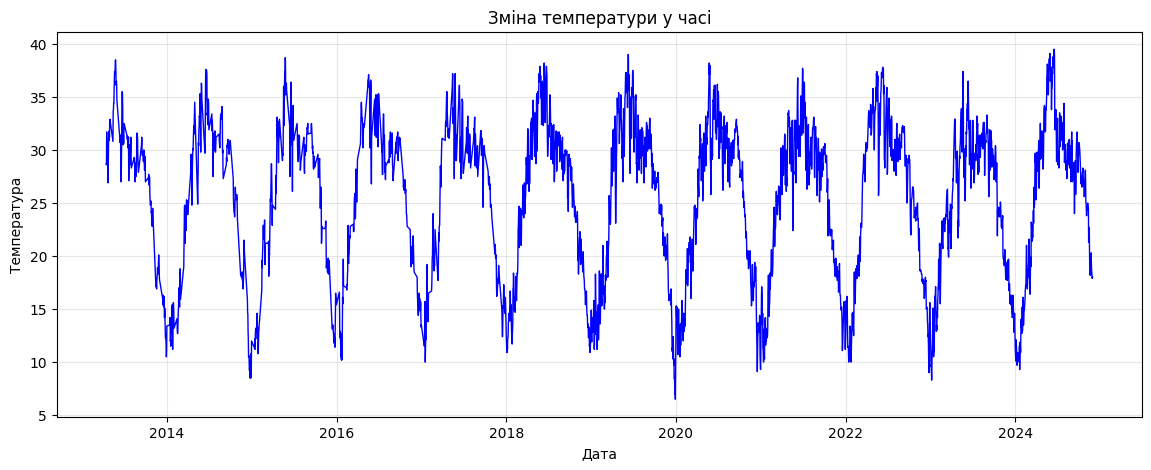

In [8]:
# Побудуйте графік зміни температури у часі
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 5))
plt.plot(df.index, df[target_col], color='blue', linewidth=1)
plt.title('Зміна температури у часі')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.grid(True, alpha=0.3)
plt.show()

Ковзне середнє

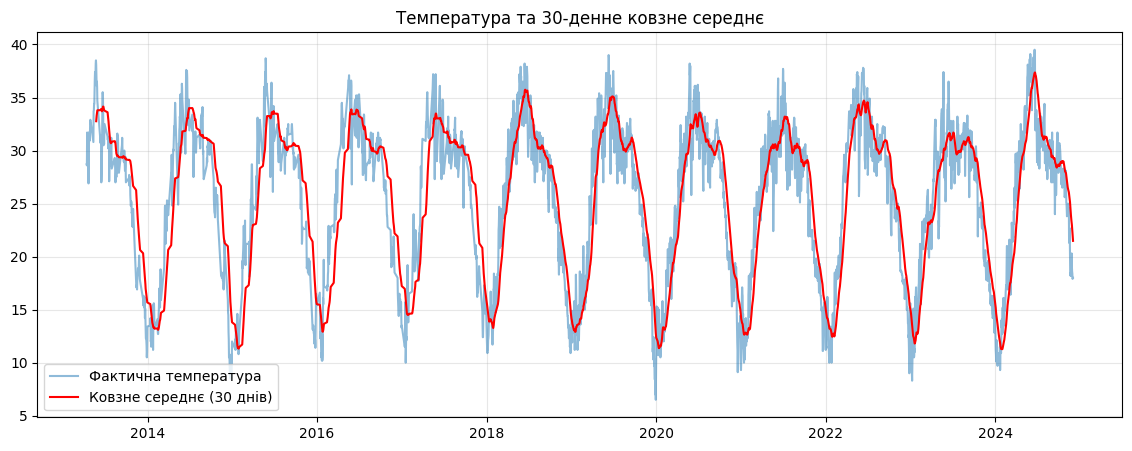

In [9]:
# Обчисліть та візуалізуйте ковзне середнє температури
plt.figure(figsize=(14, 5))
plt.plot(df.index, df[target_col], label='Фактична температура', alpha=0.5)
plt.plot(df.index, df[target_col].rolling(window=30).mean(), color='red', label='Ковзне середнє (30 днів)')
plt.title('Температура та 30-денне ковзне середнє')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Розподіл температури

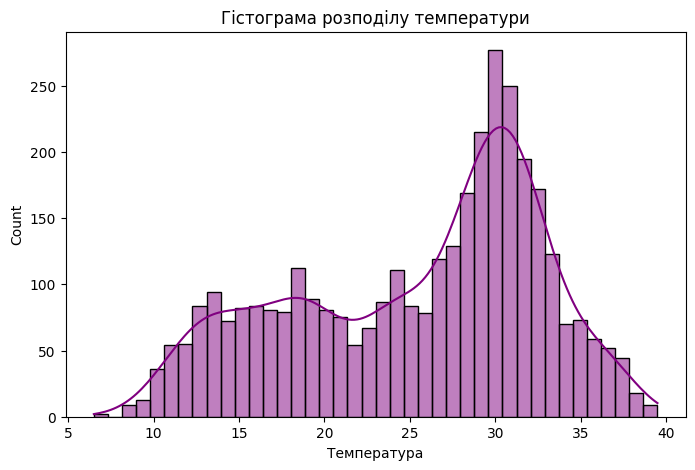

In [10]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(8, 5))
sns.histplot(df[target_col], bins=40, kde=True, color='purple')
plt.title('Гістограма розподілу температури')
plt.xlabel('Температура')
plt.show()


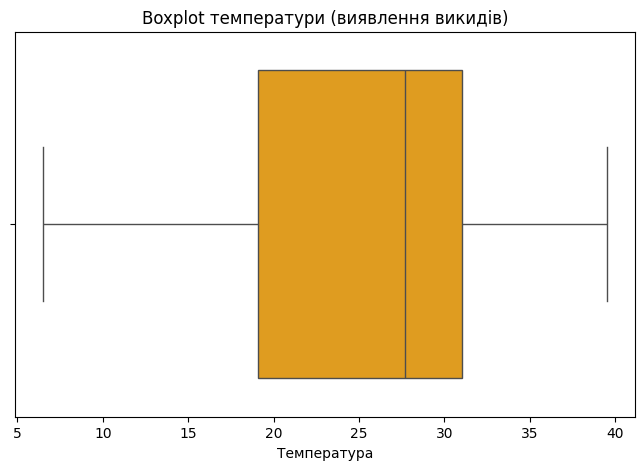

In [11]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(8, 5))
sns.boxplot(x=df[target_col], color='orange')
plt.title('Boxplot температури (виявлення викидів)')
plt.xlabel('Температура')
plt.show()

Аналіз автокореляції
ACF

PACF

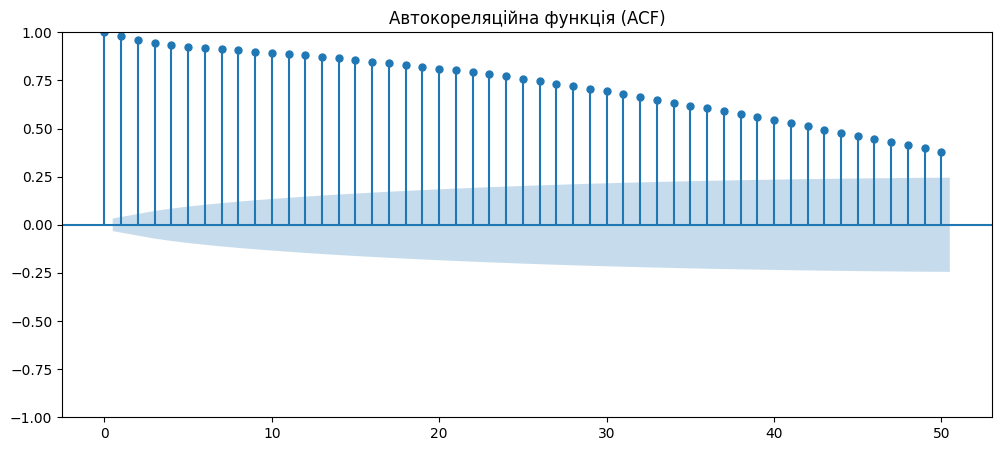

In [12]:
# Побудуйте графік автокореляційної функції (ACF)
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, ax = plt.subplots(figsize=(12, 5))
plot_acf(df[target_col].dropna(), lags=50, ax=ax)
plt.title('Автокореляційна функція (ACF)')
plt.show()


Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

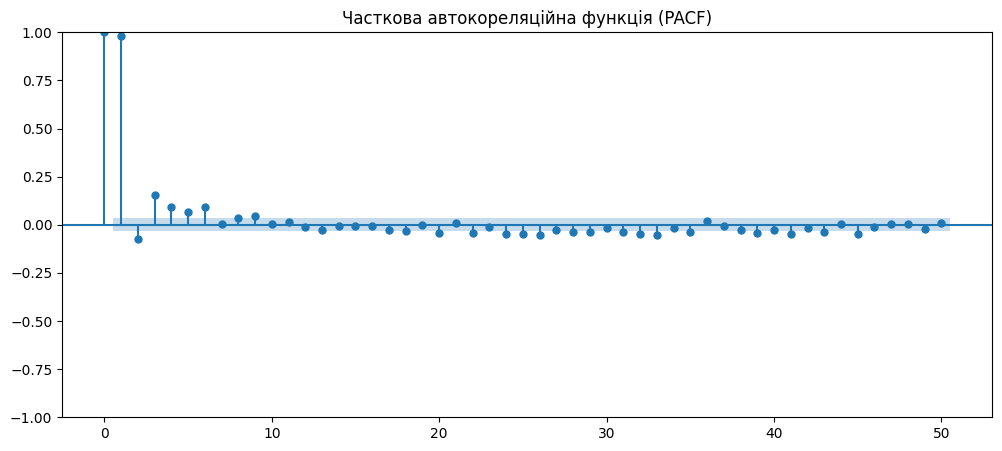

In [13]:
# Побудуйте графік часткової автокореляційної функції (PACF)
fig, ax = plt.subplots(figsize=(12, 5))
plot_pacf(df[target_col].dropna(), lags=50, ax=ax)
plt.title('Часткова автокореляційна функція (PACF)')
plt.show()


Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [14]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
train_size = int(len(df) * 0.8)
train, test = df.iloc[:train_size], df.iloc[train_size:]
print(f"Розмір тренувальної вибірки: {len(train)}")
print(f"Розмір тестової вибірки: {len(test)}")


Розмір тренувальної вибірки: 2845
Розмір тестової вибірки: 712


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [16]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
from statsmodels.tsa.arima.model import ARIMA
import pandas as pd

# Задаємо частоту індексу 'D' (Daily), щоб ARIMA знала крок часу
train.index = pd.DatetimeIndex(train.index).to_period('D')

# Параметри (p,d,q) обрані як базові (5,1,0)
arima_model = ARIMA(train[target_col], order=(5, 1, 0))
arima_result = arima_model.fit()

# Прогнозуємо на кількість кроків, що дорівнює розміру тестової вибірки
arima_forecast = arima_result.forecast(steps=len(test))

# Повертаємо прогнозу оригінальні дати з тестової вибірки для коректних графіків
arima_forecast.index = test.index

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

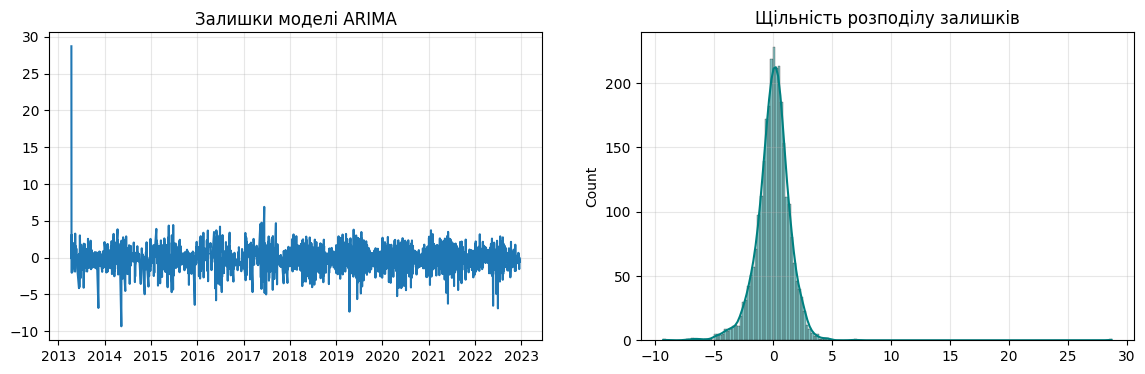

In [23]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
import matplotlib.pyplot as plt
import seaborn as sns

residuals = arima_result.resid

residuals.index = residuals.index.to_timestamp()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(residuals)
axes[0].set_title('Залишки моделі ARIMA')
axes[0].grid(True, alpha=0.3)

sns.histplot(residuals, kde=True, ax=axes[1], color='teal')
axes[1].set_title('Щільність розподілу залишків')
axes[1].grid(True, alpha=0.3)

plt.show()

In [19]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

arima_mae = mean_absolute_error(test[target_col], arima_forecast)
arima_rmse = np.sqrt(mean_squared_error(test[target_col], arima_forecast))
arima_mape = calculate_mape(test[target_col], arima_forecast)

print(f"ARIMA MAE: {arima_mae:.3f}")
print(f"ARIMA RMSE: {arima_rmse:.3f}")
print(f"ARIMA MAPE: {arima_mape:.3f}%")


ARIMA MAE: 11.096
ARIMA RMSE: 12.683
ARIMA MAPE: 40.124%


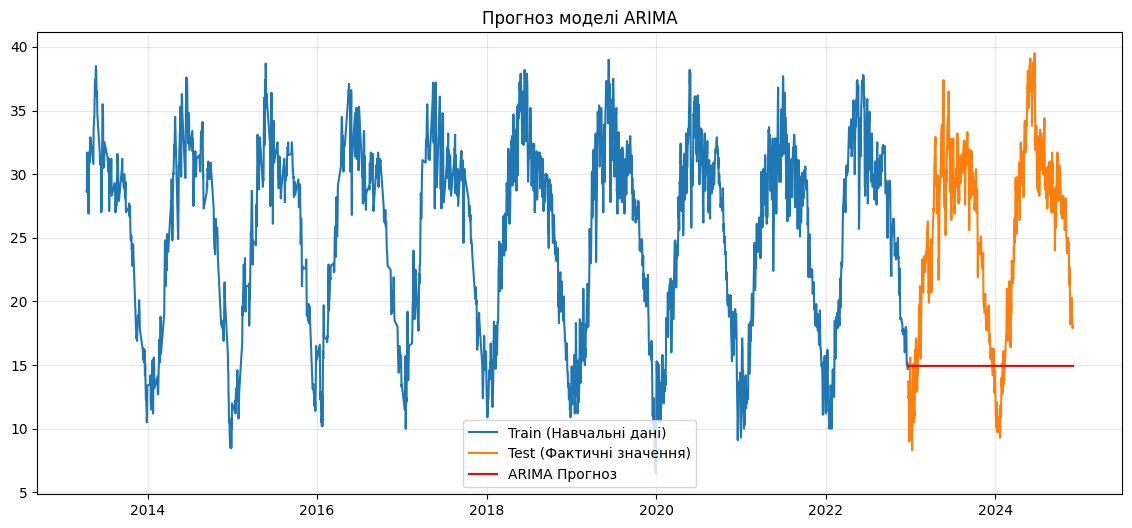

In [22]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(14, 6))

plt.plot(train.index.to_timestamp(), train[target_col], label='Train (Навчальні дані)')
plt.plot(test.index, test[target_col], label='Test (Фактичні значення)')
plt.plot(test.index, arima_forecast, color='red', label='ARIMA Прогноз')

plt.title('Прогноз моделі ARIMA')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [24]:
import pandas as pd

prophet_train = train.copy()
prophet_train.index = prophet_train.index.to_timestamp()

prophet_train = prophet_train.reset_index().rename(columns={date_col: 'ds', target_col: 'y'})
prophet_test = test.reset_index().rename(columns={date_col: 'ds', target_col: 'y'})

prophet_train.head()


,ds,y
0,2013-04-14,28.7
1,2013-04-15,28.6
2,2013-04-16,31.7
3,2013-04-17,29.9
4,2013-04-18,30.6


In [25]:
# Створіть та навчіть модель Prophet
from prophet import Prophet

prophet_model = Prophet(yearly_seasonality=True, daily_seasonality=False)

prophet_model.fit(prophet_train)


Прогноз

In [26]:
# Побудуйте прогноз Prophet для тестового періоду

future = prophet_test[['ds']]

prophet_forecast = prophet_model.predict(future)


In [27]:
# Обчисліть MAE, RMSE, MAPE для Prophet
prophet_mae = mean_absolute_error(prophet_test['y'], prophet_forecast['yhat'])
prophet_rmse = np.sqrt(mean_squared_error(prophet_test['y'], prophet_forecast['yhat']))
prophet_mape = calculate_mape(prophet_test['y'], prophet_forecast['yhat'])

print(f"Prophet MAE: {prophet_mae:.3f}")
print(f"Prophet RMSE: {prophet_rmse:.3f}")
print(f"Prophet MAPE: {prophet_mape:.3f}%")

Prophet MAE: 2.005
Prophet RMSE: 2.590
Prophet MAPE: 9.028%


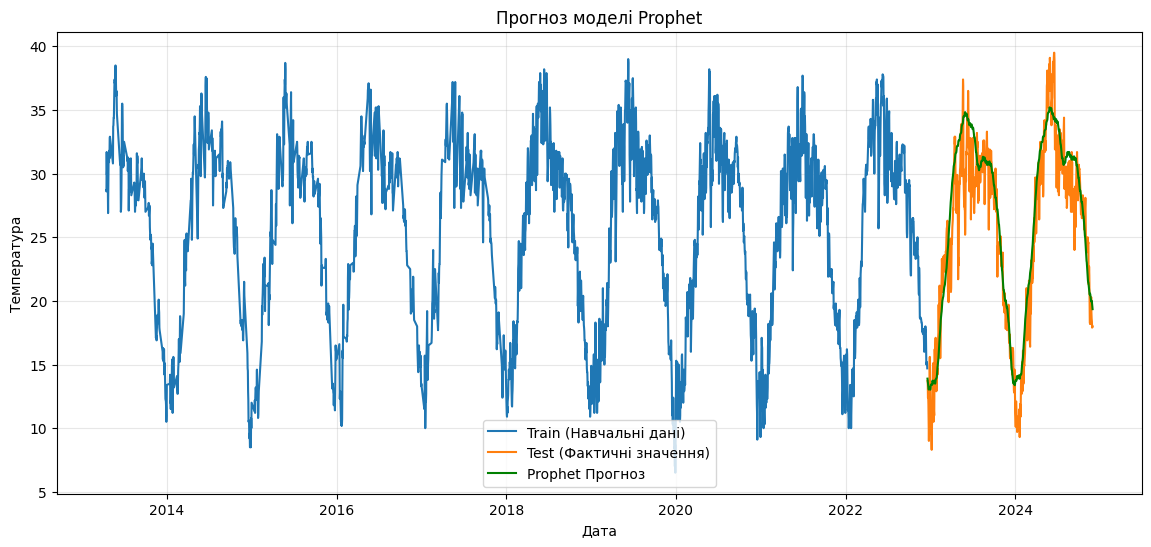

In [28]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(14, 6))

plt.plot(prophet_train['ds'], prophet_train['y'], label='Train (Навчальні дані)')
plt.plot(prophet_test['ds'], prophet_test['y'], label='Test (Фактичні значення)')
plt.plot(prophet_test['ds'], prophet_forecast['yhat'], color='green', label='Prophet Прогноз')

plt.title('Прогноз моделі Prophet')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

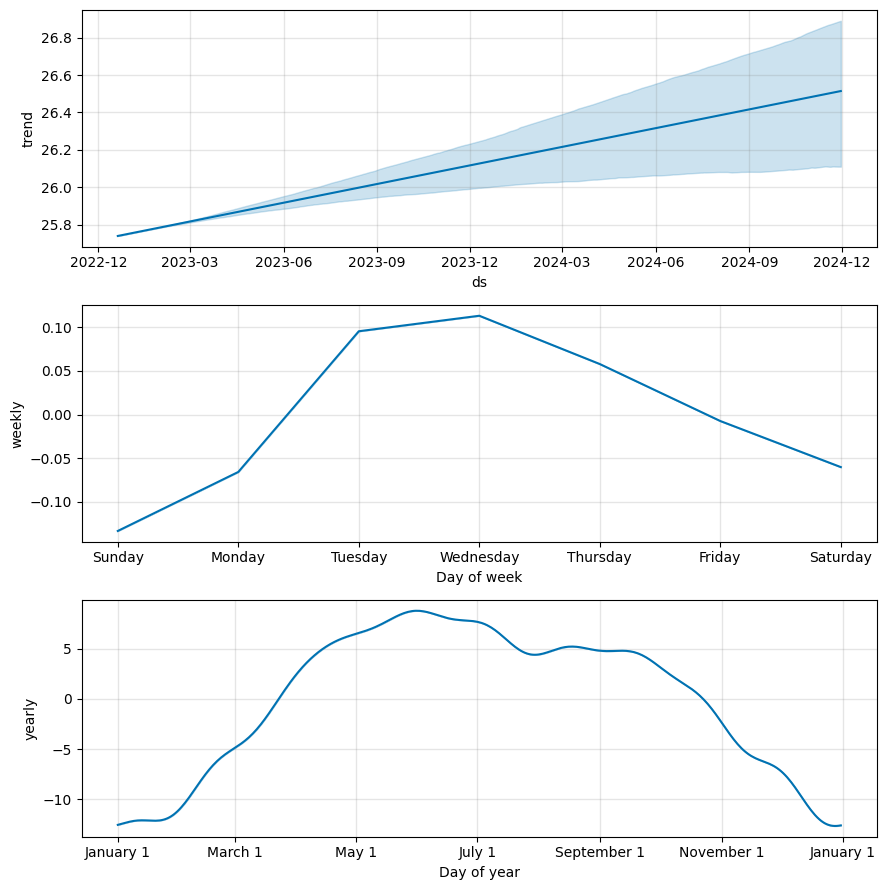

In [30]:
# Побудуйте компоненти моделі Prophet
fig = prophet_model.plot_components(prophet_forecast)
plt.show()


ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [31]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
from sklearn.preprocessing import MinMaxScaler
import numpy as np

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df[[target_col]])

def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i + seq_length])
        y.append(data[i + seq_length])
    return np.array(X), np.array(y)

SEQ_LENGTH = 30
X_seq, y_seq = create_sequences(scaled_data, SEQ_LENGTH)


In [33]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
train_size_seq = int(len(X_seq) * 0.8)

X_train_lstm = X_seq[:train_size_seq]
X_test_lstm = X_seq[train_size_seq:]

y_train_lstm = y_seq[:train_size_seq]
y_test_lstm = y_seq[train_size_seq:]

print(f"Формат X_train: {X_train_lstm.shape}")
print(f"Формат X_test: {X_test_lstm.shape}")


Формат X_train: (2821, 30, 1)
Формат X_test: (706, 30, 1)


In [34]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout

lstm_model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(SEQ_LENGTH, 1)),
    Dropout(0.2), # Dropout допомагає уникнути перенавчання
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(25),
    Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mean_squared_error')


In [35]:
# Навчіть LSTM-модель
history = lstm_model.fit(
    X_train_lstm, y_train_lstm,
    batch_size=32,
    epochs=20,
    validation_data=(X_test_lstm, y_test_lstm),
    verbose=1
)


Epoch 1/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - loss: 0.0230 - val_loss: 0.0050
Epoch 2/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0083 - val_loss: 0.0047
Epoch 3/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0074 - val_loss: 0.0042
Epoch 4/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0071 - val_loss: 0.0041
Epoch 5/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0068 - val_loss: 0.0056
Epoch 6/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0065 - val_loss: 0.0037
Epoch 7/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0058 - val_loss: 0.0035
Epoch 8/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0052 - val_loss: 0.0039
Epoch 9/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0053 - val_loss: 0.0033
Epoch 10/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0048 - val_loss: 0.0036
Epoch 11/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0045 - val_loss: 0.0029
Epoch 12/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0045 - val

In [36]:
lstm_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 95,705 (373.85 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 63,804 (249.24 KB)

In [38]:
# 1прогноз LSTM та виконайте зворотне масштабування
lstm_pred_scaled = lstm_model.predict(X_test_lstm)
lstm_predictions = scaler.inverse_transform(lstm_pred_scaled)
y_test_actual = scaler.inverse_transform(y_test_lstm.reshape(-1, 1))


23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


In [39]:
# Сформуйте часові мітки для тестового прогнозу LSTM
import pandas as pd

if not isinstance(df.index, pd.DatetimeIndex):
    df.index = df.index.to_timestamp()

lstm_test_indices = df.index[SEQ_LENGTH + train_size_seq:]

In [40]:
# Обчисліть MAE, RMSE, MAPE для LSTM
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

lstm_mae = mean_absolute_error(y_test_actual, lstm_predictions)
lstm_rmse = np.sqrt(mean_squared_error(y_test_actual, lstm_predictions))
lstm_mape = calculate_mape(y_test_actual, lstm_predictions)

print(f"LSTM MAE: {lstm_mae:.3f}")
print(f"LSTM RMSE: {lstm_rmse:.3f}")
print(f"LSTM MAPE: {lstm_mape:.3f}%")


LSTM MAE: 1.104
LSTM RMSE: 1.462
LSTM MAPE: 4.831%


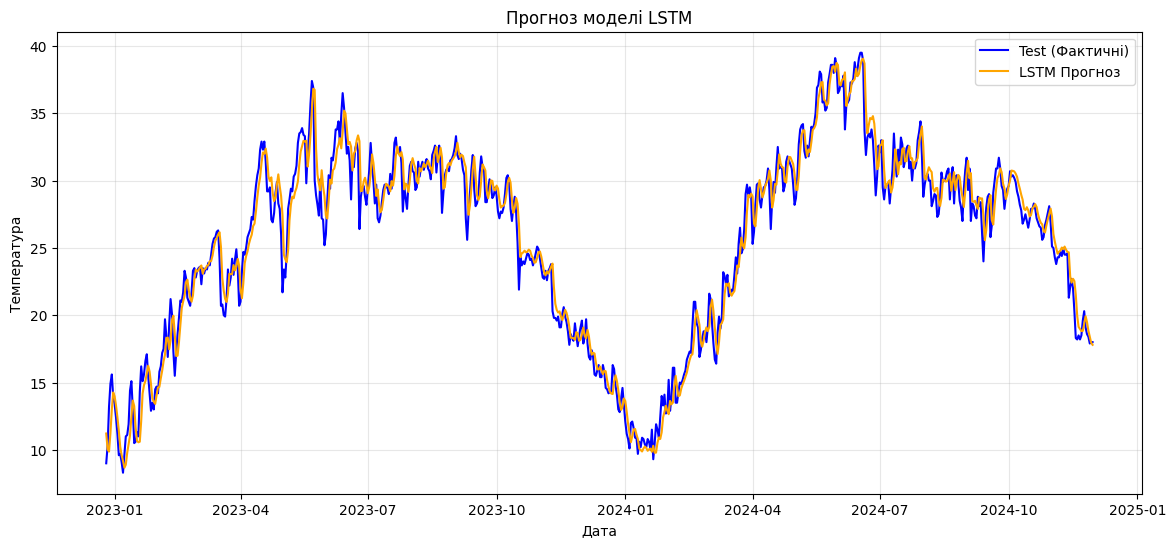

In [41]:
# Візуалізуйте фактичні значення та прогноз LSTM
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plt.plot(lstm_test_indices, y_test_actual, label='Test (Фактичні)', color='blue')
plt.plot(lstm_test_indices, lstm_predictions, color='orange', label='LSTM Прогноз')

plt.title('Прогноз моделі LSTM')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Порівняння моделей

In [43]:
import pandas as pd
comparison_data = {
    'Модель': ['ARIMA', 'Prophet', 'LSTM'],
    'MAE': [arima_mae, prophet_mae, lstm_mae],
    'RMSE': [arima_rmse, prophet_rmse, lstm_rmse],
    'MAPE (%)': [arima_mape, prophet_mape, lstm_mape]
}

comparison_df = pd.DataFrame(comparison_data).set_index('Модель')

print("--- Підсумкове порівняння ефективності моделей ---")
display(comparison_df.round(3))
best_model_name = comparison_df['MAE'].idxmin()
print(f"\nНайкраща модель за метрикою MAE: {best_model_name}")

--- Підсумкове порівняння ефективності моделей ---


,MAE,RMSE,MAPE (%)
Модель,,,
ARIMA,11.096,12.683,40.124
Prophet,2.005,2.590,9.028
LSTM,1.104,1.462,4.831



Найкраща модель за метрикою MAE: LSTM
